# 03 — Where does the group need staff?

**Goal (PROBLEM.md):** detect pressure. Every `(branch, department)` unit gets a monthly
status; pressure is expressed in operational units — appointment slots and **WTE staff**.

- **GREEN** — meets the 18-week standard (≤ 8% of waiters past 18w)
- **AMBER** — misses it, but backlog shrinking (3-month inflow ≤ outflow)
- **RED** — misses it AND backlog growing → a staffing-shortfall signal
- Stated assumption: **1 clinical WTE ≈ 200 appointments/month** (`SLOTS_PER_WTE`, adjustable)

Output: `data/processed/ops_panel.csv`. **Frozen panel:** units kept = complete on
2021-04..2026-03 (pre-registered); pre-2021 months are extra history only.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SLOTS_PER_WTE = 200  # planning assumption: appointments/month one clinical WTE delivers

long = pd.read_csv("../data/processed/rtt_long.csv")
net = json.load(open("../config/nhs_network.json"))
region_of = {t["code"]: r["region"] for r in net["regions"] for t in r["trusts"]}
icb_of = {t["code"]: t["icb"] for r in net["regions"] for t in r["trusts"]}

# one row per (branch, department, month): demand, backlog, throughput, waiting shares
key = ["provider_code", "specialty_code", "month"]
ser = ["provider_code", "specialty_code"]
cnt = long.pivot_table(index=key, columns="part", values="total_all", aggfunc="sum")
w = pd.DataFrame({"demand": cnt["Part_3"], "backlog": cnt["Part_2"],
                  "throughput": cnt["Part_1A"].fillna(0) + cnt["Part_1B"].fillna(0)}).reset_index()
bands = long[long["part"] == "Part_2"].groupby(key)[["weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum()
w = w.merge(bands.reset_index(), on=key, how="left").fillna(0)
banded = (w["weeks_0_18"] + w["weeks_18_52"] + w["weeks_52_plus"]).clip(lower=1)
w["share18"] = (w["weeks_18_52"] + w["weeks_52_plus"]) / banded
w["share52"] = w["weeks_52_plus"] / banded
w["region"] = w["provider_code"].map(region_of)
w["icb"] = w["provider_code"].map(icb_of)

# FROZEN PANEL (pre-registered): units kept = complete on 2021-04..2026-03;
# pre-2021 months are extra history only — they never add or remove a unit
WINDOW = ("2021-04", "2026-03")
months = sorted(w["month"].unique())
core = w[w["month"].between(*WINDOW)]
ok = core[core["demand"] > 0].groupby(ser)["month"].nunique()
w = w.set_index(ser).loc[ok[ok == core["month"].nunique()].index].reset_index()
w = w.sort_values(ser + ["month"]).reset_index(drop=True)

# monthly status: RED = misses standard AND backlog growing (3-month mean inflow > outflow)
w["netflow3"] = w.groupby(ser, sort=False)["demand"].transform(lambda s: s.rolling(3).mean()) - \
                w.groupby(ser, sort=False)["throughput"].transform(lambda s: s.rolling(3).mean())
w["red"] = (w["share18"] > 0.08) & (w["netflow3"] > 0)
w["flag"] = np.where(w["share18"] <= 0.08, "GREEN", np.where(w["netflow3"] > 0, "RED", "AMBER"))

w.to_csv("../data/processed/ops_panel.csv", index=False)
LAST = months[-1]
print(f"ops panel saved: {w.groupby(ser).ngroups} units x {len(months)} months | latest: {LAST}")

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})

ops panel saved: 694 units x 60 months | latest: 2026-03


flag
RED      482
AMBER    170
GREEN     42


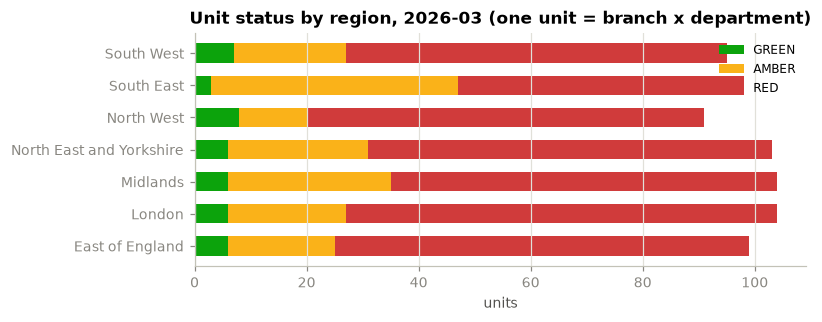

In [2]:
# current pressure map
cur = w[w["month"] == LAST]
print(cur["flag"].value_counts().to_string())

STATUS = {"GREEN": "#0ca30c", "AMBER": "#fab219", "RED": "#d03b3b"}
byreg = cur.groupby(["region", "flag"]).size().unstack(fill_value=0)[["GREEN", "AMBER", "RED"]]
fig, ax = plt.subplots(figsize=(7.5, 3))
left = np.zeros(len(byreg))
for flag in ["GREEN", "AMBER", "RED"]:
    ax.barh(byreg.index, byreg[flag], left=left, color=STATUS[flag], height=0.6, label=flag)
    left += byreg[flag].values
ax.set_title(f"Unit status by region, {LAST} (one unit = branch x department)")
ax.set_xlabel("units")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [3]:
# the staffing headline: current shortfall if recent demand persists (6-month means, RED units)
g6 = w[w["month"].isin(months[-6:])].groupby(ser)[["demand", "throughput"]].mean()
g6["gap"] = (g6["demand"] - g6["throughput"]).clip(lower=0)
red_now = cur[cur["flag"] == "RED"].set_index(ser).index
gap_red = g6.loc[g6.index.isin(red_now), "gap"]
print(f"RED units: {len(red_now)} | with positive 6-month gap: {(gap_red > 0).sum()}")
print(f"staffing shortfall at current demand: {gap_red.sum():,.0f} slots/month "
      f"= {gap_red.sum() / SLOTS_PER_WTE:,.0f} WTE across the group")
top = gap_red.sort_values(ascending=False).head(10) / SLOTS_PER_WTE
print("\nlargest single-unit shortfalls (WTE):")
print(top.round(1).to_string())

RED units: 482 | with positive 6-month gap: 458
staffing shortfall at current demand: 103,390 slots/month = 517 WTE across the group

largest single-unit shortfalls (WTE):
provider_code  specialty_code
RTE            X02               7.8
RX1            X02               6.6
RC9            C_320             6.0
RAL            X05               5.8
               X02               5.8
RTE            C_320             5.7
RX1            C_301             5.4
R0D            C_301             5.3
RAJ            C_320             5.3
               X02               4.8


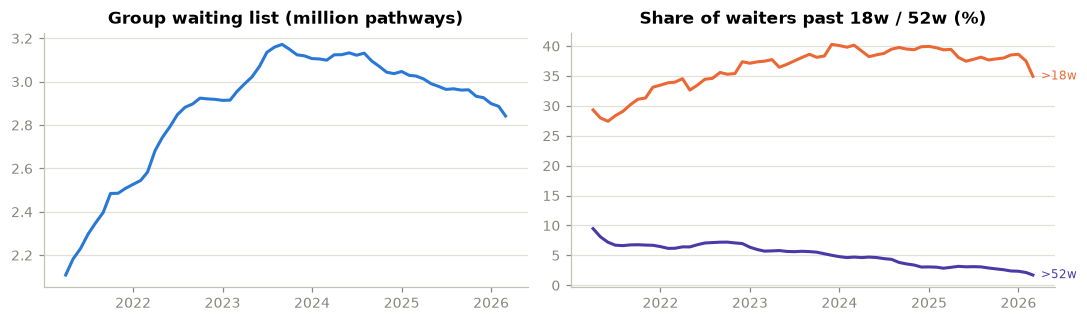

In [4]:
# how we got here: backlog level and severity over the full window
bk = w.groupby("month")[["backlog", "weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum()
banded = bk[["weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum(axis=1)
x = pd.to_datetime(bk.index)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
ax1.plot(x, bk["backlog"] / 1e6, color="#2a78d6", linewidth=2)
ax1.set_title("Group waiting list (million pathways)")
ax1.grid(axis="x", visible=False)
ax2.plot(x, 100 * bk["weeks_18_52"] / banded, color="#eb6834", linewidth=2)
ax2.plot(x, 100 * bk["weeks_52_plus"] / banded, color="#4a3aa7", linewidth=2)
ax2.text(x[-1], (100 * bk["weeks_18_52"] / banded).iloc[-1], "  >18w", color="#eb6834", va="center", fontsize=8)
ax2.text(x[-1], (100 * bk["weeks_52_plus"] / banded).iloc[-1], "  >52w", color="#4a3aa7", va="center", fontsize=8)
ax2.set_title("Share of waiters past 18w / 52w (%)")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()